In [1]:

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd


from analytics.db import query
from analytics.paths import FIGURES, RAW_WEB
from analytics.web import download
from analytics.geo import distance_km


In [2]:
query("""
      --w011
    SELECT
    INITCAP(REPLACE(p.category, '_', ' ')) AS category,
    COUNT(*) AS items,
    ROUND(( SUM(i.freight_value)::numeric/ NULLIF(SUM(i.price)::numeric, 0)) * 100,1 ) AS freight_pct
FROM clean.order_items AS i
JOIN clean.products AS p
    ON p.product_id = i.product_id
GROUP BY p.category
HAVING COUNT(*) >= 100
ORDER BY freight_pct DESC
LIMIT 5;
""")


,category,items,freight_pct
0,Christmas Supplies,153,36.7
1,Signaling And Security,199,30.3
2,Food Drink,278,29.7
3,Electronics,2767,29.1
4,Furniture Living Room,503,26.1


-- This query calculates the freight cost as a percentage
-- of total product prices for each category.
-- It includes only categories with at least 100 items,
-- sorts them by freight percentage, and returns the top 5.

In [3]:

geo = query("SELECT * FROM geolocation")

per_zip = geo.groupby("geolocation_zip_code_prefix").size()

len(geo), per_zip.size, per_zip.median(), per_zip.max()


(1000163, 19015, np.float64(29.0), np.int64(1146))

This code analyzes the geolocation table by grouping the records according to their zip code prefix. It calculates the total number of rows, the number of unique zip codes, the median number of points per zip code, and the maximum number of points associated with a single zip code. The results show that the geolocation table contains many repeated records for the same zip code.

In [4]:

customers = query("SELECT customer_id, customer_zip_code_prefix FROM clean.customers")

try:
    customers.merge(
        geo,
        left_on="customer_zip_code_prefix",
        right_on="geolocation_zip_code_prefix",
        validate="many_to_one"
    )
except pd.errors.MergeError as error:
    print(error)


Merge keys are not unique in right dataset; not a many-to-one merge

Duplicates in right:
 geolocation_zip_code_prefix
                      01046
                      01013
                      01012
                      01037
                      01046 ...


This code attempts to merge the customers table with the original geolocation table using their zip code prefixes. The left_on and right_on parameters identify the matching columns in each DataFrame. The validate="many_to_one" option checks that each zip code in the right dataset appears only once. The merge raises a MergeError because the geolocation table contains multiple points for the same zip code. This validation prevents incorrect row multiplication during the join.

## Part 1 — One Point for Each Zip Code.

In [5]:

inside = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-75, -34)

(~inside).sum()


np.int64(42)

This code identifies geolocation points that fall inside Brazil's approximate geographic boundaries using latitude and longitude. The between() function checks both coordinate ranges, while the & operator combines the conditions. The ~ operator reverses the mask to select points outside Brazil, and sum() counts those points.

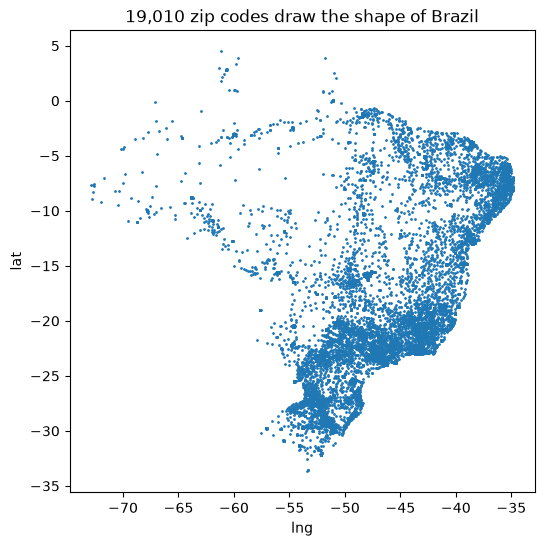

In [6]:

points = query("SELECT * FROM clean.zip_points")

ax = points.plot(
    kind="scatter",
    x="lng",
    y="lat",
    s=1,
    figsize=(6, 6)
)

ax.set_title("19,010 zip codes draw the shape of Brazil")

plt.show()


This code retrieves the cleaned zip code points from PostgreSQL and displays them using a scatter plot. Longitude is placed on the X-axis and latitude on the Y-axis. Each point represents one zip code, and together the 19,010 points form the approximate geographic shape of Brazil, with a higher concentration in the southeast.

In [7]:

sellers = query("SELECT seller_id, seller_zip_code_prefix FROM clean.sellers")

no_point_for_customers = ~customers["customer_zip_code_prefix"].isin(points["zip_prefix"])
no_point_for_sellers = ~sellers["seller_zip_code_prefix"].isin(points["zip_prefix"])
no_point_for_customers.sum(), no_point_for_sellers.sum()


(np.int64(279), np.int64(7))

This code identifies customers and sellers whose zip code is missing from the cleaned geographic points table. The isin() function checks whether each zip code exists in clean.zip_points, and the ~ operator selects those that do not. The results show 279 customers and 7 sellers without a geographic point, meaning their travel distance cannot be calculated.

In [8]:
#1.a

zip_1146 = per_zip.idxmax()

zip_1146_geo = geo[
    geo["geolocation_zip_code_prefix"] == zip_1146
]

state_counts = zip_1146_geo["geolocation_state"].value_counts()
city_counts = zip_1146_geo["geolocation_city"].value_counts()

print("Zip code:", zip_1146)
print("State counts:")
print(state_counts)
print("\nMost common cities:")
print(city_counts.head(10))


Zip code: 24220
State counts:
geolocation_state
RJ    1146
Name: count, dtype: int64

Most common cities:
geolocation_city
niteroi    997
niterói    149
Name: count, dtype: int64


This code identifies the zip code with the maximum number of geolocation points using idxmax(). It filters the original geolocation DataFrame to keep only the records belonging to that zip code. The value_counts() function is then used to count the occurrences of each state and city, helping identify the most common state and city.

In [9]:
#1.b

state_counts_all = (
    geo.groupby(
        ["geolocation_zip_code_prefix", "geolocation_state"]
    )
    .size()
    .rename("points")
    .reset_index()
)

states_per_zip = geo.groupby(
    "geolocation_zip_code_prefix"
)["geolocation_state"].nunique()

two_state_zips = states_per_zip[states_per_zip == 2].index

two_state_results = state_counts_all[
    state_counts_all["geolocation_zip_code_prefix"].isin(two_state_zips)
].sort_values(
    ["geolocation_zip_code_prefix", "points"],
    ascending=[True, False]
)

two_state_results


,geolocation_zip_code_prefix,geolocation_state,points
368,02116,SP,12
367,02116,RN,1
1670,04011,SP,178
1669,04011,AC,1
6509,21550,RJ,170
6508,21550,AC,1
6700,23056,RJ,60
6699,23056,AC,1
14669,72915,GO,40
14668,72915,DF,1


This code identifies zip codes that have geographic points in exactly two different states. It first counts the points for each zip code and state combination, then uses nunique() to find zip codes associated with two states. The results are filtered and sorted to compare the number of points in each state and determine whether one state is clearly more common.

## Part 2 — Measuring Distance.

In [10]:
center = points.set_index("zip_prefix").loc[["01001", "20010"]]

distance_km(
    center["lat"].iloc[0],
    center["lng"].iloc[0],
    center["lat"].iloc[1],
    center["lng"].iloc[1]
)

np.float64(360.67018667440504)

This cell tests the distance function using two known locations in Brazil: São Paulo and Rio de Janeiro. The calculated straight-line distance is approximately 360.7 km, which helps verify that the function works correctly.

In [11]:
trips = query("""
    SELECT i.order_id, i.freight_value, p.product_weight_g,
           c.customer_state, c.customer_zip_code_prefix AS customer_zip_prefix,
           s.seller_zip_code_prefix AS seller_zip_prefix,
           o.order_purchase_timestamp, o.order_delivered_customer_date
    FROM clean.order_items AS i
    JOIN clean.orders AS o ON o.order_id = i.order_id
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
    JOIN clean.sellers AS s ON s.seller_id = i.seller_id
    JOIN clean.products AS p ON p.product_id = i.product_id
""")

places = points[["zip_prefix", "lat", "lng"]]

trips = (
    trips
    .merge(
        places.add_prefix("customer_"),
        on="customer_zip_prefix",
        how="left",
        validate="many_to_one"
    )
    .merge(
        places.add_prefix("seller_"),
        on="seller_zip_prefix",
        how="left",
        validate="many_to_one"
    )
)

trips["distance_km"] = distance_km(
    trips["seller_lat"],
    trips["seller_lng"],
    trips["customer_lat"],
    trips["customer_lng"]
)

len(trips), trips["distance_km"].isna().sum(), trips["distance_km"].median()

(112650, np.int64(555), np.float64(431.714755102471))

This cell combines order, customer, seller, and product information with the ZIP Code coordinates. It calculates the distance between each seller and customer in kilometers. The resulting dataset contains 112,650 items, with 555 missing distances and a median distance of 431.7 km.

In [12]:
#2.a
seller_states = points[["zip_prefix", "state"]].rename(
    columns={
        "zip_prefix": "seller_zip_prefix",
        "state": "seller_state"
    }
)

trips_with_seller_state = trips.merge(
    seller_states,
    on="seller_zip_prefix",
    how="left",
    validate="many_to_one"
)

longest_trip = trips_with_seller_state.loc[
    trips_with_seller_state["distance_km"].idxmax()
]

longest_trip[
    ["distance_km", "seller_state", "customer_state"]
]

distance_km       3579.339684
seller_state               SC
customer_state             RR
Name: 102781, dtype: object

This exercise identifies the longest delivery trip and shows the states of the seller and customer. The seller's state is added using the ZIP Code location table, and the row with the maximum distance is selected.

In [13]:
#2.b
valid_distances = trips["distance_km"].notna()

under_100 = trips.loc[valid_distances, "distance_km"] < 100

under_100.sum(), round(
    under_100.sum() / valid_distances.sum() * 100,
    1
)

(np.int64(20986), np.float64(18.7))

This exercise counts the items that traveled less than 100 km and calculates their percentage among all items with a valid distance. Missing distances are excluded from the calculation.

## Part 3 — Does Distance Explain Freight and Delivery Time

In [14]:
trips["delivery_days"] = (
    trips["order_delivered_customer_date"]
    - trips["order_purchase_timestamp"]
).dt.total_seconds() / 86400

This cell calculates the delivery time for each item by subtracting the purchase timestamp from the delivery timestamp. The result is converted from seconds into days and stored in a new column called `delivery_days`.

In [15]:
trips["band"] = pd.cut(
    trips["distance_km"],
    [0, 100, 300, 600, 1000, 1500, 2000, 5000],
    right=False
)

by_band = trips.groupby("band").agg(
    items=("freight_value", "size"),
    freight=("freight_value", "mean"),
    delivery_days=("delivery_days", "mean"),
).round(2)

by_band

,items,freight,delivery_days
band,,,
"[0, 100)",20986,11.75,6.53
"[100, 300)",15588,16.40,9.90
"[300, 600)",36956,19.58,12.54
"[600, 1000)",20883,21.78,14.63
"[1000, 1500)",7613,26.22,17.16
"[1500, 2000)",3644,35.44,19.40
"[2000, 5000)",6425,35.92,21.09


This cell groups items into distance ranges using `pd.cut()`. It then calculates the number of items, average freight cost, and average delivery time for each distance group. This allows us to compare shipping costs and delivery times across different trip lengths.

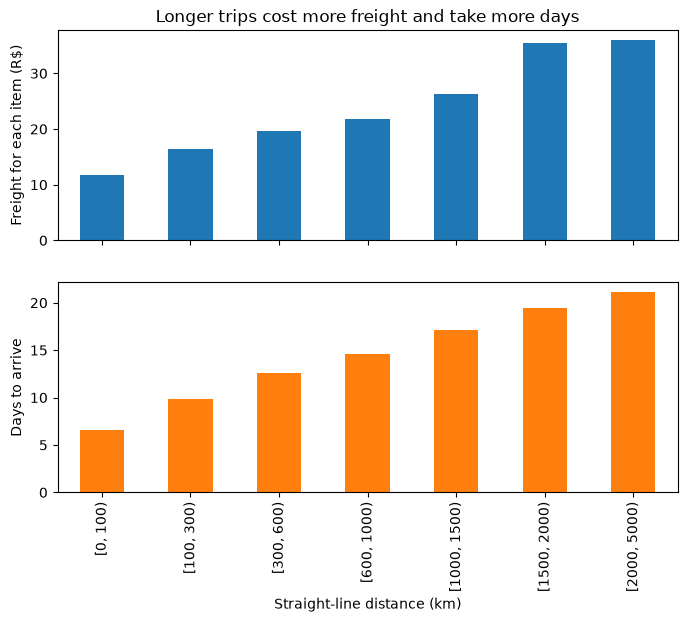

In [16]:
fig, (top, bottom) = plt.subplots(
    2, 1,
    sharex=True,
    figsize=(8, 6)
)

by_band["freight"].plot(kind="bar", ax=top)

top.set_title("Longer trips cost more freight and take more days")
top.set_ylabel("Freight for each item (R$)")

by_band["delivery_days"].plot(
    kind="bar",
    ax=bottom,
    color="tab:orange"
)

bottom.set_ylabel("Days to arrive")
bottom.set_xlabel("Straight-line distance (km)")

fig.savefig(
    FIGURES / "day-11-distance.png",
    bbox_inches="tight"
)

plt.show()

These charts compare average freight cost and delivery time across distance bands. Both measures generally increase as the distance becomes longer. However, the calculated distances are straight-line estimates and do not represent the actual delivery routes.

In [17]:
#a.3
exact_30000 = trips.loc[
    trips["product_weight_g"] == 30000,
    "freight_value"
].median()

between_25000_29999 = trips.loc[
    trips["product_weight_g"].between(25000, 29999),
    "freight_value"
].median()

exact_30000, between_25000_29999

(np.float64(104.06), np.float64(80.515))

This exercise compares the median freight cost of items weighing exactly 30,000 g with items weighing between 25,000 g and 29,999 g. The comparison helps investigate whether the 30,000 g weight value may represent a recorded limit for some products.

In [18]:
#3.b
light_trips = trips.loc[
    trips["product_weight_g"] < 1000
].copy()

light_trips["band"] = pd.cut(
    light_trips["distance_km"],
    [0, 100, 300, 600, 1000, 1500, 2000, 5000],
    right=False
)

light_by_band = light_trips.groupby("band").agg(
    items=("freight_value", "size"),
    freight=("freight_value", "mean"),
    delivery_days=("delivery_days", "mean"),
).round(2)

light_by_band

,items,freight,delivery_days
band,,,
"[0, 100)",13834,9.08,5.95
"[100, 300)",8706,12.67,9.53
"[300, 600)",21223,15.64,12.15
"[600, 1000)",11978,17.38,14.30
"[1000, 1500)",4382,20.60,16.64
"[1500, 2000)",2182,28.27,18.68
"[2000, 5000)",4017,29.35,20.33


This exercise filters the dataset to include only items weighing less than 1 kg. It then groups the items by distance and calculates the average freight cost and delivery time for each group to check whether distance still affects shipping costs for lightweight products.

## Part 4: Maps of Brazil

In [19]:
STATES_URL = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/brazil-states.geojson"

states_path = RAW_WEB / "maps" / "brazil-states.geojson"

download(states_path, STATES_URL)

states = gpd.read_file(states_path)

states.shape

(27, 9)

Downloaded the Brazil states GeoJSON file and loaded it using GeoPandas. The resulting GeoDataFrame contains 27 geographic regions, including their state codes and boundary geometries.

In [20]:
orders = query("""
    SELECT c.customer_state AS state,
           o.order_purchase_timestamp AS purchase,
           o.order_delivered_customer_date AS delivered,
           o.order_estimated_delivery_date AS estimated
    FROM clean.orders AS o
    JOIN clean.customers AS c ON c.customer_id = o.customer_id
""")

arrived = orders.dropna(subset=["delivered"])

late = arrived["delivered"].dt.normalize() > arrived["estimated"].dt.normalize()

by_state = pd.DataFrame({
    "orders": orders.groupby("state").size(),
    "late_pct": 100 * late.groupby(arrived["state"]).mean(),
    "freight": trips.groupby("customer_state")["freight_value"].mean(),
})

by_state.loc[["SP", "AL", "AM"]].round(1)

,orders,late_pct,freight
SP,41746,4.5,15.1
AL,413,21.4,35.8
AM,148,2.8,33.2


Calculated three metrics for each Brazilian state: total orders, the percentage of orders delivered after the estimated date, and average freight cost per item. Grouped the data by state and compared the results for SP, AL, and AM.

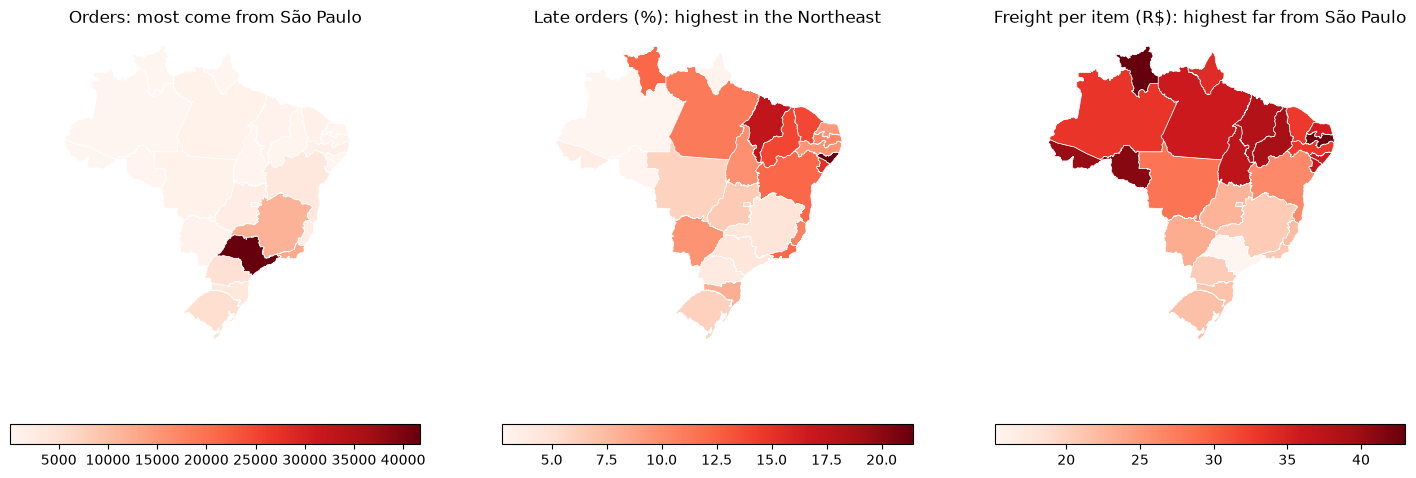

In [21]:
states = states.merge(
    by_state,
    left_on="sigla",
    right_index=True,
    how="left",
    validate="one_to_one"
)

maps = [
    ("orders", "Orders: most come from São Paulo"),
    ("late_pct", "Late orders (%): highest in the Northeast"),
    ("freight", "Freight per item (R$): highest far from São Paulo"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (column, title) in zip(axes, maps):
    states.plot(
        column=column,
        cmap="Reds",
        legend=True,
        legend_kwds={"orientation": "horizontal"},
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )
    ax.set_title(title)
    ax.set_axis_off()

fig.savefig(FIGURES / "day-11-maps.png", bbox_inches="tight")
plt.show()

Merged the state-level statistics with the geographic boundaries using the state codes. Created three choropleth maps to show the distribution of orders, late delivery percentages, and average freight costs across Brazil. Saved the maps as `day-11-maps.png`.

In [22]:
#4.a
orders["promised_days"] = (
    orders["estimated"] - orders["purchase"]
).dt.total_seconds() / 86400

orders.groupby("state")["promised_days"].mean().loc[["AM", "AL"]].round(1)

state
AM    45.1
AL    32.6
Name: promised_days, dtype: float64

In [23]:
#4.b
arrived["delivery_days"] = (
    arrived["delivered"] - arrived["purchase"]
).dt.total_seconds() / 86400

avg_days = arrived.groupby("state")["delivery_days"].mean()

avg_days.sort_values(ascending=False).head()

state
RR    29.387546
AP    27.185068
AM    26.425991
AL    24.543855
PA    23.772917
Name: delivery_days, dtype: float64